In [1]:
import sys

sys.path.append("../src")
import torch
from datasets.bird_call_photo_latent_mix import BirdCallPhotoLatentMix
from models.diffusion import Diffusion
from models.vae import VAE
from processing.audio import log_mel_to_waveform
from IPython.display import Audio, display
from torchvision.transforms.functional import to_pil_image

/home/rmdluo/miniconda3/envs/birdcallbirdphoto/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
AUDIO_DATASET_PATH = "../data/iNaturalistLatentsContrastiveAudio"
PHOTO_DATASET_PATH = "../data/iNaturalistLatentsPhoto"
AUDIO_VAE_CHECKPOINT_PATH = (
    "../models/contrastive_audio_vae/1785588335498284773/contrastive_audio_vae_final.tar"
)
PHOTO_VAE_CHECKPOINT_PATH = (
    "../models/photo_vae/1784935571103765988/photo_vae_final.tar"
)
PHOTO_DIFFUSION_CHECKPOINT_PATH = "../models/contrastive_conditional_photo_diffusion/1785617075648407339/contrastive_conditional_photo_diffusion_final.tar"

diffusion_checkpoint = torch.load(PHOTO_DIFFUSION_CHECKPOINT_PATH, weights_only=False, map_location="cpu")
vae_checkpoint = torch.load(PHOTO_VAE_CHECKPOINT_PATH, weights_only=False, map_location="cpu")

diffusion_parameters = diffusion_checkpoint['model_parameters']
vae_parameters = vae_checkpoint['model_parameters']
train_parameters = diffusion_checkpoint['train_parameters']
train_parameters.device = "cuda:1"

In [3]:
train_dataset = BirdCallPhotoLatentMix(
    AUDIO_DATASET_PATH,
    PHOTO_DATASET_PATH,
    AUDIO_VAE_CHECKPOINT_PATH,
    PHOTO_VAE_CHECKPOINT_PATH,
    split="train",
    audio_first=False,
    num_pairs_per_species=50,
)
val_dataset = BirdCallPhotoLatentMix(
    AUDIO_DATASET_PATH,
    PHOTO_DATASET_PATH,
    AUDIO_VAE_CHECKPOINT_PATH,
    PHOTO_VAE_CHECKPOINT_PATH,
    split="val",
    audio_first=False,
    num_pairs_per_species=50,
)

In [4]:
diffusion = Diffusion(diffusion_parameters)
diffusion.load_state_dict(diffusion_checkpoint['model_state_dict'])
diffusion = diffusion.to(train_parameters.device)
diffusion.eval()

Diffusion(
  (embed_conditioning): Sequential(
    (0): Conv2d(4, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): GroupNorm(8, 64, eps=1e-05, affine=True)
    (2): SiLU()
    (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (4): GroupNorm(16, 128, eps=1e-05, affine=True)
    (5): SiLU()
    (6): Conv2d(128, 1024, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (diffusion): UNet2DConditionModel(
    (conv_in): Conv2d(4, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (time_proj): Timesteps()
    (time_embedding): TimestepEmbedding(
      (linear_1): Linear(in_features=128, out_features=512, bias=True)
      (act): SiLU()
      (linear_2): Linear(in_features=512, out_features=512, bias=True)
    )
    (down_blocks): ModuleList(
      (0): CrossAttnDownBlock2D(
        (attentions): ModuleList(
          (0-1): 2 x Transformer2DModel(
            (norm): GroupNorm(32, 128, eps=1e-06, affine=True)
            (proj_in): Conv2d

In [5]:
vae = VAE(vae_parameters)
vae.load_state_dict(vae_checkpoint['model_state_dict'])
vae = vae.to(train_parameters.device)
vae.eval()

VAE(
  (encoder): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(1, 1), padding=(3, 3))
    (1): ResidualBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
      (act1): SiLU()
      (act2): SiLU()
      (norm1): GroupNorm(8, 64, eps=1e-05, affine=True)
      (norm2): GroupNorm(8, 64, eps=1e-05, affine=True)
      (residual): Identity()
    )
    (2): ResidualBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
      (act1): SiLU()
      (act2): SiLU()
      (norm1): GroupNorm(8, 64, eps=1e-05, affine=True)
      (norm2): GroupNorm(8, 64, eps=1e-05, affine=True)
      (residual): Identity()
    )
    (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (4): ResidualBlock(
      (conv1): Conv2d(128, 128, kernel_size=(3, 3), st

Abert's Towhee


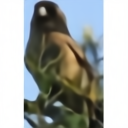

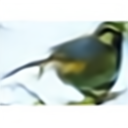

In [6]:
latent_1, latent_2, species = val_dataset[0]
latent_1 = latent_1.to(train_parameters.device)
latent_2 = latent_2.to(train_parameters.device)

samples = diffusion.sample(latent_2.unsqueeze(0), dif_steps=50, device=train_parameters.device)

print(species)

with torch.no_grad():
    photo_example_of_original = vae.decode(latent_1.unsqueeze(0).to(train_parameters.device))
    photo_generated = vae.decode(samples[-1].to(train_parameters.device))

display(to_pil_image((photo_example_of_original[0]).clamp(0, 1)))
display(to_pil_image((photo_generated[0]).clamp(0, 1)))

American Pipit


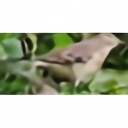

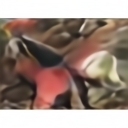

In [7]:
latent_1, latent_2, species = val_dataset[100]
latent_1 = latent_1.to(train_parameters.device)
latent_2 = latent_2.to(train_parameters.device)

samples = diffusion.sample(latent_2.unsqueeze(0), device=train_parameters.device)

print(species)

with torch.no_grad():
    photo_example_of_original = vae.decode(latent_1.unsqueeze(0).to(train_parameters.device))
    photo_generated = vae.decode(samples[-1].to(train_parameters.device))

display(to_pil_image((photo_example_of_original[0]).clamp(0, 1)))
display(to_pil_image((photo_generated[0]).clamp(0, 1)))

Australasian Figbird


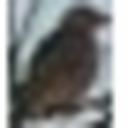

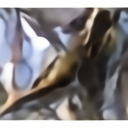

In [8]:
latent_1, latent_2, species = val_dataset[200]
latent_1 = latent_1.to(train_parameters.device)
latent_2 = latent_2.to(train_parameters.device)

samples = diffusion.sample(latent_2.unsqueeze(0), device=train_parameters.device)

print(species)

with torch.no_grad():
    photo_example_of_original = vae.decode(latent_1.unsqueeze(0).to(train_parameters.device))
    photo_generated = vae.decode(samples[-1].to(train_parameters.device))

display(to_pil_image((photo_example_of_original[0]).clamp(0, 1)))
display(to_pil_image((photo_generated[0]).clamp(0, 1)))

Bar-shouldered Dove
Noised 25 steps
Random latent vs actual latent: tensor(1.0935, device='cuda:1')
0.009063417091965675
0.00011302294296910986
Correct MSE: 1.8225826025009155
Random MSE: 1.8227885961532593


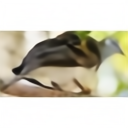

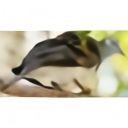

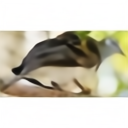

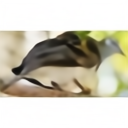

Noised 50 steps
Random latent vs actual latent: tensor(0.9777, device='cuda:1')
0.02682778239250183
0.0003460905863903463
Correct MSE: 1.6833043098449707
Random MSE: 1.6838868856430054


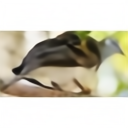

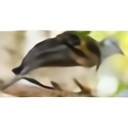

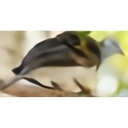

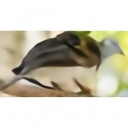

Noised 100 steps
Random latent vs actual latent: tensor(1.0833, device='cuda:1')
0.08815159648656845
0.0011898549273610115
Correct MSE: 1.422670841217041
Random MSE: 1.424363613128662


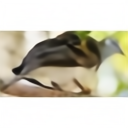

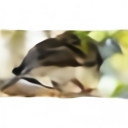

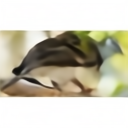

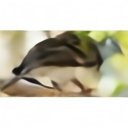

Noised 200 steps
Random latent vs actual latent: tensor(1.0104, device='cuda:1')
0.27707037329673767
0.0009324526763521135
Correct MSE: 1.0756866931915283
Random MSE: 1.0766897201538086


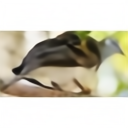

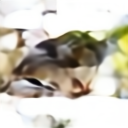

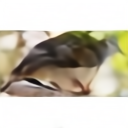

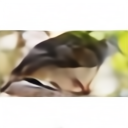

Noised 300 steps
Random latent vs actual latent: tensor(1.0023, device='cuda:1')
0.47227755188941956
-0.0035981095861643553
Correct MSE: 0.7045657634735107
Random MSE: 0.7020306587219238


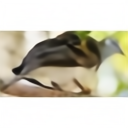

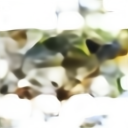

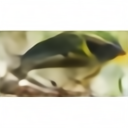

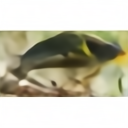

Noised 500 steps
Random latent vs actual latent: tensor(1.0504, device='cuda:1')
0.9691922664642334
-0.039058245718479156
Correct MSE: 0.5054948329925537
Random MSE: 0.48575109243392944


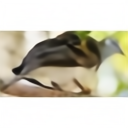

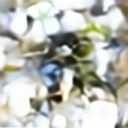

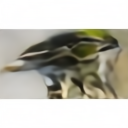

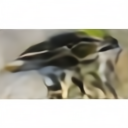

Noised 800 steps
Random latent vs actual latent: tensor(1.0549, device='cuda:1')
1.729227900505066
-0.11025120317935944
Correct MSE: 0.4765583872795105
Random MSE: 0.4240172505378723


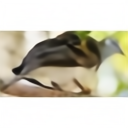

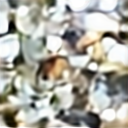

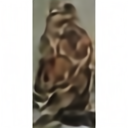

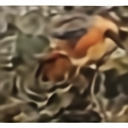

Noised 999 steps
Random latent vs actual latent: tensor(1.0354, device='cuda:1')
1.1985445022583008
0.08184877783060074
Correct MSE: 0.5617150068283081
Random MSE: 0.607690691947937


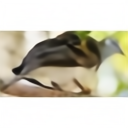

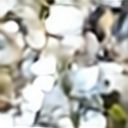

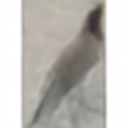

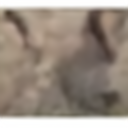

In [9]:
latent_1, latent_2, species = val_dataset[300]
latent_1 = latent_1.unsqueeze(0).to(train_parameters.device)
latent_2 = latent_2.unsqueeze(0).to(train_parameters.device)

print(species)

for start_t in [25, 50, 100, 200, 300, 500, 800, 999]:
    print(f"Noised {start_t} steps")
    t = torch.tensor([start_t], device=train_parameters.device, dtype=torch.long)
    noise = torch.randn_like(latent_1)

    z_t = diffusion.scheduler.add_noise(latent_1, noise, t)

    samples = diffusion.sample(
        latent_2,
        device=train_parameters.device,
        init_latents=z_t,
        start_timestep=start_t,
        dif_steps=100,
    )

    random_latent = torch.randn_like(latent_2)
    print("Random latent vs actual latent:", torch.nn.functional.mse_loss(latent_2, random_latent))

    samples2 = diffusion.sample(
        random_latent,
        device=train_parameters.device,
        init_latents=z_t,
        start_timestep=start_t,
        dif_steps=100,
    )

    correct_error = torch.nn.functional.mse_loss(
        samples[-1],
        noise.to("cpu"),
    )

    random_error = torch.nn.functional.mse_loss(
        samples2[-1],
        noise.to("cpu"),
    )

    relative_loss_gap = (
        random_error - correct_error
    ) / correct_error.clamp_min(1e-8)

    latent_error = torch.nn.functional.mse_loss(
        samples[-1].to(train_parameters.device),
        latent_1,
    )

    print(latent_error.item())
    print(relative_loss_gap.item())
    print("Correct MSE:", correct_error.item())
    print("Random MSE:", random_error.item())

    with torch.no_grad():
        photo_original = vae.decode(latent_1)
        photo_noised = vae.decode(z_t)
        photo_reconstructed = vae.decode(samples[-1].to(train_parameters.device))
        photo_reconstructed_random = vae.decode(samples2[-1].to(train_parameters.device))

    display(to_pil_image(photo_original[0].clamp(0, 1)))
    display(to_pil_image(photo_noised[0].clamp(0, 1)))
    display(to_pil_image(photo_reconstructed[0].clamp(0, 1)))
    display(to_pil_image(photo_reconstructed_random[0].clamp(0, 1)))

# Plotting Loss Curves

In [10]:
%matplotlib inline

import pandas as pd
import seaborn as sns

epochs = len(diffusion_checkpoint['train_losses']['total_loss'])
losses = pd.DataFrame({
    "total_losses": diffusion_checkpoint['train_losses']['total_loss'] + diffusion_checkpoint['val_losses']['total_loss'],
    "split": ["train"] * epochs + ["val"] * epochs,
    "epoch": list(range(epochs)) + list(range(epochs))
})

<Axes: xlabel='epoch', ylabel='total_losses'>

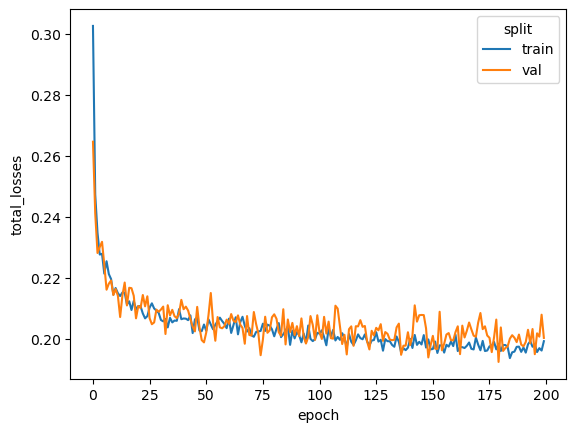

In [11]:
sns.lineplot(
    losses,
    x="epoch",
    y="total_losses",
    hue="split"
)